# Pricing a Bermudan Put with Longstaff–Schwartz
## Monte Carlo *vs* Quasi-Monte Carlo: the role of path construction

**Alexandre Saad El Din** — MSc Probability and Finance (Sorbonne Université / École Polytechnique)

---

**Abstract.** We price a Bermudan put (50 exercise dates) under Black–Scholes with the Longstaff–Schwartz algorithm, feeding it two kinds of paths: pseudo-random (Monte Carlo) and low-discrepancy (Sobol sequence, Quasi-Monte Carlo). For QMC, we compare two constructions of Brownian motion: the sequential construction (Cholesky) and the principal component decomposition (PCA). Prices are validated against a Bermudan CRR binomial tree.

**Results.**
- With $N = 2^{16}$ paths, QMC with the PCA construction is about **5 times more accurate** than MC on the Bermudan put (error 0.002 vs an RMSE of 0.011).
- On the European put computed from the same paths, the gain rises to about **50 times**: the exercise boundary, which makes the integrand discontinuous, strongly reduces the advantage of QMC.
- With the same Sobol points, the **Cholesky** construction does worse than MC as long as $N \le 2^{13}$: the path construction, not the sequence itself, decides how well QMC performs.
- The regression bias of Longstaff–Schwartz sets an error floor that QMC cannot break through: the degree of the regression basis matters as much as the number of paths.

### Contents

1. Setting and parameters
2. Path simulation: Cholesky and PCA, MC and QMC
3. Reference prices: Black–Scholes and a Bermudan binomial tree
4. The Longstaff–Schwartz algorithm
5. Numerical experiments
6. Conclusion and extensions

**References.**
- G. Pagès, *Numerical Probability: An Introduction with Applications to Finance*, Springer, 2018.
- F. Longstaff, E. Schwartz, *Valuing American Options by Simulation: A Simple Least-Squares Approach*, Review of Financial Studies, 2001.
- P. Glasserman, *Monte Carlo Methods in Financial Engineering*, Springer, 2003.

---
## 1. Setting and parameters

Under the risk-neutral measure, the underlying follows a geometric Brownian motion with continuous dividend yield $q$:

$$dS_t = (r - q)\,S_t\,dt + \sigma\,S_t\,dW_t .$$

We consider a **Bermudan put** with strike $K$ and maturity $T$, exercisable at the dates $t_k = k\,T/d$, $k = 1, \dots, d$. Its price is

$$V_0 = \sup_{\tau \in \mathcal{T}} \mathbb{E}\left[ e^{-r\tau}\, h(S_\tau) \right], \qquad h(s) = (K - s)^+,$$

where $\mathcal{T}$ is the set of stopping times taking values in $\{t_1, \dots, t_d\}$.

**Why a Bermudan?** A simulation method only knows the path at the simulated dates, so Longstaff–Schwartz always prices a Bermudan option. The American option is its limit as $d \to \infty$.

The parameters are those of the benchmark example in Longstaff and Schwartz (2001).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, qmc

# Plot style
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "lines.linewidth": 2,
})
COLOR_MC = "#2a78d6"     # blue
COLOR_CHOL = "#eb6834"   # orange
COLOR_PCA = "#1baf7a"    # aqua
COLOR_REF = "#8a8984"    # grey

In [2]:
# Market and contract parameters
S0 = 36.0       
K = 40.0        
r = 0.06        
q = 0.0         
sigma = 0.2     
T = 1.0         

# Numerical parameters
d = 50          # number of exercise dates = dimension of the QMC problem
DEGREE = 4      # degree of the regression polynomial in Longstaff-Schwartz

In [3]:
def put_payoff(S):
    """Put payoff: (K - S)^+."""
    return np.maximum(K - S, 0.0)


def call_payoff(S):
    """Call payoff: (S - K)^+."""
    return np.maximum(S - K, 0.0)

---
## 2. Path simulation

### 2.1 One formula for every construction

At the dates $t_1 < \dots < t_d$, the vector $(W_{t_1}, \dots, W_{t_d})$ is a centred Gaussian vector with covariance

$$C_{ij} = \min(t_i, t_j).$$

For **any** matrix $A$ such that $A A^\top = C$ and $Z \sim \mathcal{N}(0, I_d)$, the vector $W = A Z$ has the right law. The price then follows from

$$S_{t_k} = S_0 \exp\Big( \big(r - q - \tfrac{\sigma^2}{2}\big)\, t_k + \sigma\, W_{t_k} \Big).$$

We compare two choices of $A$:

- **Cholesky**: $A$ is lower triangular. On a uniform grid, $A_{ij} = \sqrt{\Delta t}\,\mathbf{1}_{j \le i}$, i.e. $W_{t_k} = \sum_{j \le k} \sqrt{\Delta t}\, Z_j$: this is the usual step-by-step simulation. Every coordinate $Z_j$ carries the same weight.
- **PCA**: we diagonalise $C = V \Lambda V^\top$ with $\lambda_1 \ge \dots \ge \lambda_d$ and set $A = V \Lambda^{1/2}$. Coordinate $Z_1$ then carries the direction of largest variance, $Z_2$ the next one, and so on. This is the discrete version of the Karhunen–Loève expansion.

**In Monte Carlo, the choice of $A$ makes no difference**: the $Z_j$ are i.i.d., hence interchangeable. **In Quasi-Monte Carlo, it changes everything**: the first coordinates of a Sobol sequence are far better distributed than the last ones. PCA puts the variance of the problem where QMC is most accurate: it reduces the *effective dimension*.

In [4]:
def time_grid(d):
    """Exercise dates t_k = k T / d, for k = 1, ..., d."""
    return T * np.arange(1, d + 1) / d


def brownian_covariance(d):
    """Covariance matrix C_ij = min(t_i, t_j) of Brownian motion at t_1, ..., t_d."""
    t = time_grid(d)
    C = np.zeros((d, d))
    for i in range(d):
        for j in range(d):
            C[i, j] = min(t[i], t[j])
    return C


def build_A(d, method):
    """Matrix A such that A A^T = C, for the chosen construction ('cholesky' or 'pca')."""
    C = brownian_covariance(d)

    if method == "cholesky":
        A = np.linalg.cholesky(C)

    elif method == "pca":
        eigenvalues, eigenvectors = np.linalg.eigh(C)
        order = np.argsort(eigenvalues)[::-1]
        eigenvalues = eigenvalues[order]
        eigenvectors = eigenvectors[:, order]
        A = eigenvectors @ np.diag(np.sqrt(eigenvalues))

    else:
        raise ValueError("method must be 'cholesky' or 'pca'")

    return A

In [5]:
# Check: A A^T must give back C for both constructions
C_test = brownian_covariance(5)
for method in ["cholesky", "pca"]:
    A_test = build_A(5, method)
    error = np.max(np.abs(A_test @ A_test.T - C_test))
    print(f"{method:>8}: max |A A^T - C| = {error:.2e}")
print("Expected: errors of order 1e-16.")

cholesky: max |A A^T - C| = 2.78e-17
     pca: max |A A^T - C| = 5.55e-16
Expected: errors of order 1e-16.


### 2.2 Monte Carlo and Quasi-Monte Carlo Gaussians

- **MC**: we draw $Z \sim \mathcal{N}(0, I_d)$ directly with a pseudo-random generator.
- **QMC**: we take the first $N = 2^m$ points of the (unscrambled) Sobol sequence in dimension $d$, then apply the inverse Gaussian CDF coordinate by coordinate: $Z = \Phi^{-1}(U)$.

Three precautions:
1. Use $\Phi^{-1}$ and **not** Box–Muller, which mixes coordinates and destroys the structure of the sequence.
2. The first Sobol point is $(0, \dots, 0)$ and $\Phi^{-1}(0) = -\infty$: we skip it.
3. Always take $N$ equal to a power of 2: that is where the equidistribution properties of Sobol are guaranteed.

One row of $Z$ is one path; one column is one Sobol dimension. With Cholesky, column $k$ drives the increment at date $t_k$; with PCA, it drives the $k$-th principal component. Columns correspond to dates only after $W = Z A^\top$.

In [6]:
def gaussian_mc(n_paths, d, seed):
    """(n_paths, d) matrix of i.i.d. standard Gaussians (pseudo-random)."""
    rng = np.random.default_rng(seed)
    return rng.standard_normal((n_paths, d))


def gaussian_qmc(m, d):
    """(2^m, d) matrix obtained by applying Phi^{-1} to Sobol points (first point skipped)."""
    sobol = qmc.Sobol(d=d, scramble=False)
    sobol.fast_forward(1)          # skip the point (0, ..., 0)
    U = sobol.random(2**m)         # random_base2 refuses to run after fast_forward
    return norm.ppf(U)


def simulate_paths(Z, A, d):
    """Paths of the underlying at t_1, ..., t_d: (n_paths, d) matrix."""
    t = time_grid(d)
    W = Z @ A.T                                  # each row: W = A z
    drift = (r - q - 0.5 * sigma**2) * t
    S = S0 * np.exp(drift + sigma * W)
    return S

### 2.3 Effective dimension: variance explained by the PCA

The share of variance carried by the first $k$ components is $\sum_{i \le k} \lambda_i / \sum_i \lambda_i$. In the continuous limit (Karhunen–Loève), the eigenvalues of Brownian motion on $[0, T]$ are

$$\lambda_k = \frac{T^2}{(k - \tfrac12)^2 \pi^2},$$

so they decay like $1/k^2$, **independently of the number of dates $d$**. The first component alone carries $8/\pi^2 \approx 81\%$ of the variance.

Note: this curve concerns $W$, not the payoff. It is a proxy for the effective dimension in the truncation sense (exact for a payoff linear in $W$), not an exact ANOVA computation.

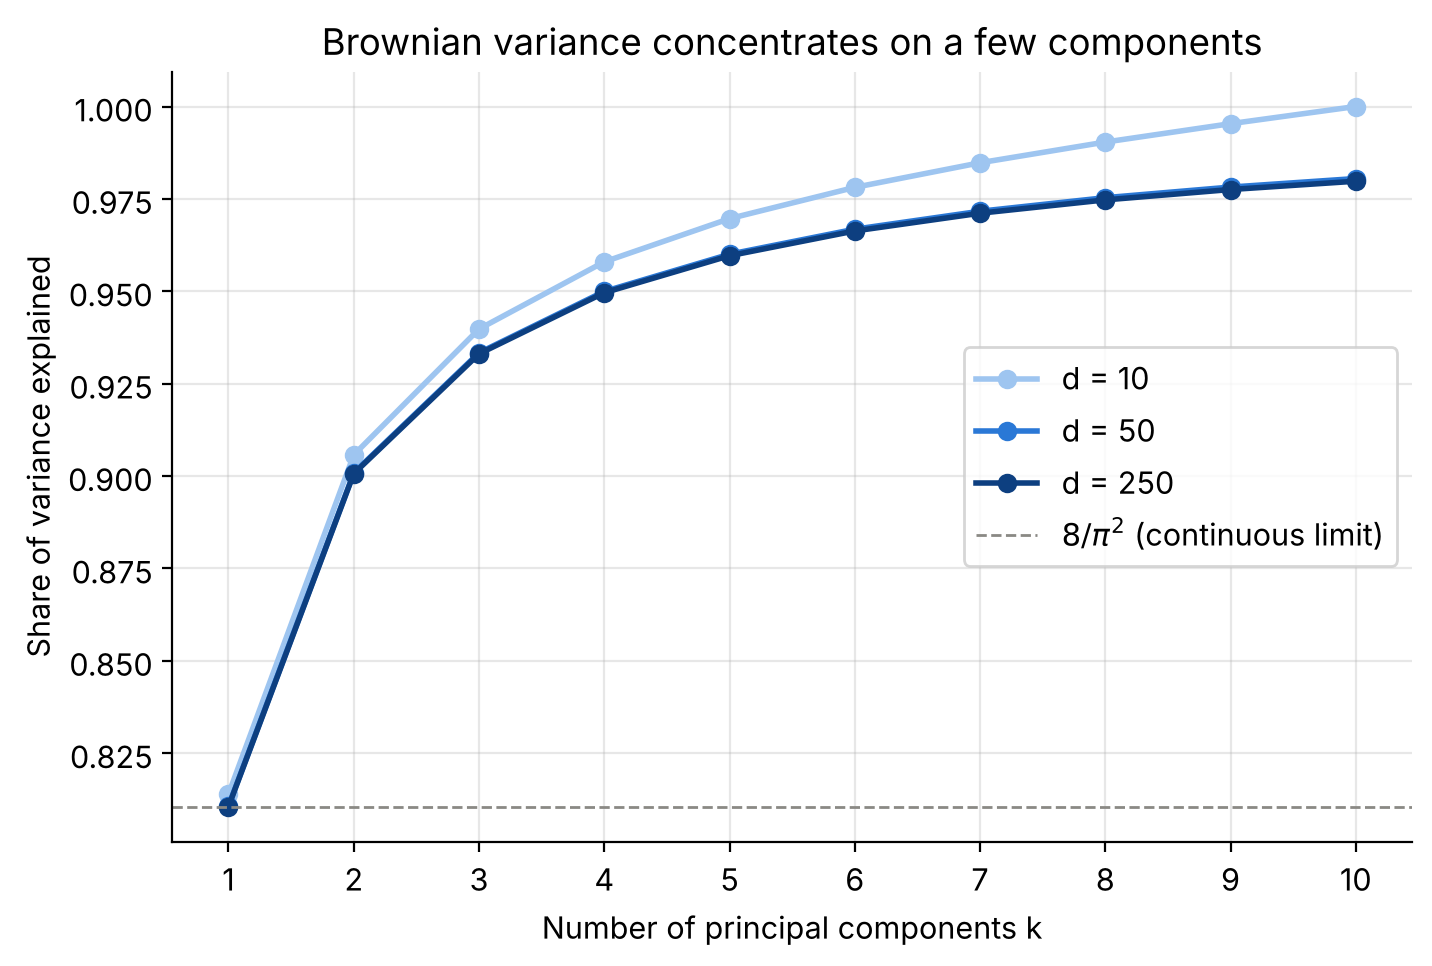

d = 50: 1 component -> 81.1%, 3 components -> 93.3%, 10 components -> 98.1%


In [7]:
fig, ax = plt.subplots()
colors = ["#9ec5f0", "#2a78d6", "#0d3f80"]   # lighter to darker as d grows
d_list = [10, 50, 250]

for i in range(len(d_list)):
    eigenvalues = np.linalg.eigvalsh(brownian_covariance(d_list[i]))
    eigenvalues = np.sort(eigenvalues)[::-1]
    explained = np.cumsum(eigenvalues) / np.sum(eigenvalues)
    ax.plot(np.arange(1, 11), explained[:10], marker="o", color=colors[i], label=f"d = {d_list[i]}")

ax.axhline(8 / np.pi**2, color=COLOR_REF, linestyle="--", linewidth=1, label=r"$8/\pi^2$ (continuous limit)")
ax.set_xlabel("Number of principal components k")
ax.set_ylabel("Share of variance explained")
ax.set_title("Brownian variance concentrates on a few components")
ax.set_xticks(np.arange(1, 11))
ax.legend()
plt.show()

eigenvalues = np.sort(np.linalg.eigvalsh(brownian_covariance(d)))[::-1]
explained = np.cumsum(eigenvalues) / np.sum(eigenvalues)
print(f"d = {d}: 1 component -> {explained[0]:.1%}, 3 components -> {explained[2]:.1%}, 10 components -> {explained[9]:.1%}")

---
## 3. Reference prices

### 3.1 Black–Scholes (European)

Used for testing only:

$$P^{\text{euro}} = K e^{-rT} \Phi(-d_2) - S_0 e^{-qT} \Phi(-d_1), \qquad d_{1,2} = \frac{\ln(S_0/K) + (r - q \pm \sigma^2/2)\,T}{\sigma\sqrt{T}} .$$

In [8]:
def bs_price(kind):
    d1 = (np.log(S0 / K) + (r - q + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if kind == "call":
        return S0 * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    elif kind == "put":
        return K * np.exp(-r * T) * norm.cdf(-d2) - S0 * np.exp(-q * T) * norm.cdf(-d1)
    else:
        raise ValueError("kind must be 'call' or 'put'")


print(f"European put (BS)  : {bs_price('put'):.4f}")
print(f"European call (BS) : {bs_price('call'):.4f}")

European put (BS)  : 3.8443
European call (BS) : 2.1737


### 3.2 Bermudan CRR binomial tree

With $n$ time steps $\delta = T/n$:

$$u = e^{\sigma\sqrt{\delta}}, \qquad \bar u = 1/u, \qquad p = \frac{e^{(r-q)\delta} - \bar u}{u - \bar u}.$$

At node $(k, j)$ (step $k$, $j$ down-moves), $S = S_0\, u^{k-j}\, \bar u^{\,j}$, and we go backward through the tree with

$$V_k(j) = e^{-r\delta}\big(p\,V_{k+1}(j) + (1-p)\,V_{k+1}(j+1)\big), \qquad \text{then } V_k(j) \leftarrow \max\big(V_k(j),\, h(S)\big) \text{ if step } k \text{ is an exercise date.}$$

**Key point**: exercise is only allowed at the $d$ dates $t_k = kT/d$ (so $n$ must be a multiple of $d$). Otherwise we would be comparing Longstaff–Schwartz (Bermudan) with an American price, and the measured "error" would include the Bermudan/American gap.

Tree prices oscillate slightly with the parity of $n$: we average two trees of neighbouring sizes.

In [9]:
def crr_price(n_steps, n_exercise, payoff):
    """Price with a CRR tree.

    n_exercise = 0          : European option
    n_exercise = d          : Bermudan option exercisable at t_k = k T / d (k = 1, ..., d)
    n_exercise = n_steps    : (quasi-)American option, exercisable at every step
    """
    if n_exercise > 0 and n_steps % n_exercise != 0:
        raise ValueError("n_steps must be a multiple of n_exercise")

    delta = T / n_steps
    u = np.exp(sigma * np.sqrt(delta))
    u_bar = 1.0 / u
    p = (np.exp((r - q) * delta) - u_bar) / (u - u_bar)
    discount = np.exp(-r * delta)

    # Values at maturity
    j = np.arange(n_steps + 1)
    S = S0 * u**(n_steps - j) * u_bar**j
    V = payoff(S)

    # Backward induction
    for k in range(n_steps - 1, -1, -1):
        V = discount * (p * V[:-1] + (1 - p) * V[1:])
        if n_exercise > 0 and k > 0 and k % (n_steps // n_exercise) == 0:
            j = np.arange(k + 1)
            S = S0 * u**(k - j) * u_bar**j
            V = np.maximum(V, payoff(S))

    return V[0]


def reference_price(d, payoff):
    """Bermudan reference price: average of two trees of neighbouring sizes."""
    n1 = 5000
    n2 = 5000 + d
    return 0.5 * (crr_price(n1, d, payoff) + crr_price(n2, d, payoff))

### 3.3 Tree checks

1. **Without early exercise**, the tree must converge to Black–Scholes.
2. **Merton's theorem**: without dividends ($q = 0$), it is never optimal to exercise a call before maturity. The Bermudan call must therefore equal the European call.
3. **Stability**: the Bermudan price no longer moves at the 3rd decimal as $n$ grows.

In [10]:
# Check
print(f"European put : tree {crr_price(5000, 0, put_payoff):.4f} | BS {bs_price('put'):.4f}")
print(f"Bermudan call (q = 0): tree {crr_price(5000, d, call_payoff):.4f} | European call BS {bs_price('call'):.4f}")
print()
for n in [1000, 2000, 5000, 10000]:
    print(f"Bermudan put, n = {n:>5} steps: {crr_price(n, d, put_payoff):.5f}")

European put : tree 3.8444 | BS 3.8443
Bermudan call (q = 0): tree 2.1738 | European call BS 2.1737

Bermudan put, n =  1000 steps: 4.47842
Bermudan put, n =  2000 steps: 4.47802
Bermudan put, n =  5000 steps: 4.47792


Bermudan put, n = 10000 steps: 4.47787


In [11]:
V_REF = reference_price(d, put_payoff)
print(f"Reference price of the Bermudan put ({d} dates): V_REF = {V_REF:.4f}")

Reference price of the Bermudan put (50 dates): V_REF = 4.4779


### 3.4 Bermudan *vs* American, and Richardson extrapolation

The gap between a Bermudan with $d$ dates and the American option is of order $1/d$:

$$V^{\text{amer}} = V^{\text{berm}}_d + \frac{c}{d} + o\!\left(\frac{1}{d}\right) \quad \Longrightarrow \quad V^{\text{amer}} \approx 2\,V^{\text{berm}}_{2d} - V^{\text{berm}}_d .$$

This is Richardson–Romberg extrapolation (Pagès, chapter on discretisation schemes): it removes the first-order term without increasing $d$.

In [12]:
V_berm_50 = crr_price(5000, 50, put_payoff)
V_berm_100 = crr_price(5000, 100, put_payoff)
V_amer = 0.5 * (crr_price(5000, 5000, put_payoff) + crr_price(5001, 5001, put_payoff))
V_richardson = 2 * V_berm_100 - V_berm_50

print(f"Bermudan,  50 dates          : {V_berm_50:.4f}   (gap to American: {V_amer - V_berm_50:.4f})")
print(f"Bermudan, 100 dates          : {V_berm_100:.4f}   (gap to American: {V_amer - V_berm_100:.4f})")
print(f"Richardson 2 V_100 - V_50    : {V_richardson:.4f}   (gap to American: {V_amer - V_richardson:.4f})")
print(f"American (tree, 5000 steps)  : {V_amer:.4f}")

Bermudan,  50 dates          : 4.4779   (gap to American: 0.0088)
Bermudan, 100 dates          : 4.4823   (gap to American: 0.0043)
Richardson 2 V_100 - V_50    : 4.4868   (gap to American: -0.0001)
American (tree, 5000 steps)  : 4.4867


---
## 4. The Longstaff–Schwartz algorithm

### 4.1 Principle

The Bermudan price is given by dynamic programming (Snell envelope):

$$V_{t_d} = h(S_{t_d}), \qquad V_{t_k} = \max\Big( h(S_{t_k}),\; C_k(S_{t_k}) \Big), \qquad C_k(s) = \mathbb{E}\big[ e^{-r\Delta t}\, V_{t_{k+1}} \,\big|\, S_{t_k} = s \big].$$

The whole difficulty is to estimate the **continuation value** $C_k$. Longstaff and Schwartz approximate it by least-squares regression on a polynomial basis, **using in-the-money paths only** (the only ones where the exercise decision arises):

$$\hat C_k(s) = \sum_{j=0}^{p} \hat\beta^{(k)}_j \left(\frac{s}{K}\right)^j, \qquad \hat\beta^{(k)} = \arg\min_{\beta} \sum_{i \,:\, h(S^i_{t_k}) > 0} \Big( Y^i - \sum_{j=0}^{p} \beta_j \big(S^i_{t_k}/K\big)^j \Big)^2,$$

where $Y^i$ is the **realised** (discounted) future cash flow of path $i$, under the exercise strategy already estimated at later dates.

### 4.2 Algorithm

1. Initialisation: $\text{CF}^i = h(S^i_{t_d})$.
2. For $k = d-1, \dots, 1$:
    - discount one step: $\text{CF}^i \leftarrow e^{-r\Delta t}\,\text{CF}^i$;
    - regress $\text{CF}$ on the basis, over in-the-money paths;
    - if $h(S^i_{t_k}) > \hat C_k(S^i_{t_k})$: exercise, i.e. $\text{CF}^i \leftarrow h(S^i_{t_k})$.
3. Price: $\hat V_0 = e^{-r\Delta t}\,\frac{1}{N}\sum_{i} \text{CF}^i$.

In [13]:
def regression_basis(x, degree):
    """Regression matrix (n, degree + 1): columns 1, x, x^2, ..., x^degree."""
    X = np.ones((len(x), degree + 1))
    for j in range(1, degree + 1):
        X[:, j] = x**j
    return X


def lsm_price(S, payoff, degree, early_exercise=True):
    """Bermudan price by Longstaff-Schwartz.

    S: paths (n_paths, d) at t_1, ..., t_d (MC or QMC, it does not matter).
    early_exercise = False: exercise at maturity only (European price, useful for testing).
    """
    n_paths, d = S.shape
    dt = T / d
    discount = np.exp(-r * dt)

    # Cash flows at maturity
    cashflow = payoff(S[:, d - 1])

    # Backward induction over the dates t_{d-1}, ..., t_1 (indices d-2, ..., 0)
    for k in range(d - 2, -1, -1):
        cashflow = discount * cashflow

        if not early_exercise:
            continue

        exercise_value = payoff(S[:, k])
        itm = exercise_value > 0
        if np.sum(itm) <= degree + 1:
            continue

        # Regression of the continuation value, on in-the-money paths
        X = regression_basis(S[itm, k] / K, degree)
        beta = np.linalg.lstsq(X, cashflow[itm], rcond=None)[0]
        continuation = X @ beta

        # Exercise where the immediate payoff exceeds the estimated continuation value
        itm_indices = np.where(itm)[0]
        exercise_indices = itm_indices[exercise_value[itm] > continuation]
        cashflow[exercise_indices] = exercise_value[exercise_indices]

    # Discount from t_1 to t_0
    return discount * np.mean(cashflow)

### 4.3 Checks

1. Without early exercise, we must recover the Black–Scholes European put.
2. Merton: the call (with $q = 0$) must recover the European call, even with early exercise allowed.
3. The Bermudan put price must be close to $V_{\text{REF}}$.

In [14]:
# Check
A_chol = build_A(d, "cholesky")
A_pca = build_A(d, "pca")
S_test = simulate_paths(gaussian_mc(2**16, d, seed=42), A_chol, d)

print(f"Put, no early exercise     : LSM {lsm_price(S_test, put_payoff, DEGREE, early_exercise=False):.4f} | BS {bs_price('put'):.4f}")
print(f"Call with exercise (q = 0) : LSM {lsm_price(S_test, call_payoff, DEGREE):.4f} | BS {bs_price('call'):.4f}")
print(f"Bermudan put               : LSM {lsm_price(S_test, put_payoff, DEGREE):.4f} | tree {V_REF:.4f}")
print("Expected: gaps of order 0.01 to 0.03 (Monte Carlo error with 65,536 paths).")

Put, no early exercise     : LSM 3.8196 | BS 3.8443


Call with exercise (q = 0) : LSM 2.1890 | BS 2.1737


Bermudan put               : LSM 4.4698 | tree 4.4779
Expected: gaps of order 0.01 to 0.03 (Monte Carlo error with 65,536 paths).


---
## 5. Numerical experiments

(Unrandomised) QMC is **deterministic**: it has no variance and no confidence interval. We therefore measure its error directly against the tree, for each $N = 2^m$. For MC, we repeat $M$ independent runs and compute an RMSE:

$$\text{err}_{\text{QMC}}(N) = \big|\hat V_0^{\text{QMC}}(N) - V_{\text{REF}}\big|, \qquad \text{RMSE}_{\text{MC}}(N) = \sqrt{\frac{1}{M}\sum_{j=1}^{M} \big(\hat V_0^{(j)}(N) - V_{\text{REF}}\big)^2}.$$

For a given $N$, MC and QMC use exactly the same Longstaff–Schwartz algorithm: only the paths change.

### 5.1 Convergence: MC *vs* QMC Cholesky *vs* QMC PCA

In [15]:
m_values = np.arange(8, 17)       # N = 2^8, ..., 2^16
n_runs = 20                       # number of independent MC runs for the RMSE

rmse_mc = np.zeros(len(m_values))
err_qmc_chol = np.zeros(len(m_values))
err_qmc_pca = np.zeros(len(m_values))

for i in range(len(m_values)):
    m = m_values[i]

    # Monte Carlo: n_runs independent estimates
    prices_mc = np.zeros(n_runs)
    for j in range(n_runs):
        Z = gaussian_mc(2**m, d, seed=1000 * m + j)
        prices_mc[j] = lsm_price(simulate_paths(Z, A_chol, d), put_payoff, DEGREE)
    rmse_mc[i] = np.sqrt(np.mean((prices_mc - V_REF)**2))

    # Quasi-Monte Carlo: a single (deterministic) estimate per construction
    Z = gaussian_qmc(m, d)
    err_qmc_chol[i] = abs(lsm_price(simulate_paths(Z, A_chol, d), put_payoff, DEGREE) - V_REF)
    err_qmc_pca[i] = abs(lsm_price(simulate_paths(Z, A_pca, d), put_payoff, DEGREE) - V_REF)

    print(f"N = 2^{m:<2} | RMSE MC {rmse_mc[i]:.4f} | error QMC Cholesky {err_qmc_chol[i]:.4f} | error QMC PCA {err_qmc_pca[i]:.4f}")

N = 2^8  | RMSE MC 0.1973 | error QMC Cholesky 0.4631 | error QMC PCA 0.1540
N = 2^9  | RMSE MC 0.2005 | error QMC Cholesky 0.4231 | error QMC PCA 0.0673


N = 2^10 | RMSE MC 0.1253 | error QMC Cholesky 0.2766 | error QMC PCA 0.0153


N = 2^11 | RMSE MC 0.0640 | error QMC Cholesky 0.2289 | error QMC PCA 0.0104


N = 2^12 | RMSE MC 0.0300 | error QMC Cholesky 0.1287 | error QMC PCA 0.0354


N = 2^13 | RMSE MC 0.0298 | error QMC Cholesky 0.0579 | error QMC PCA 0.0224


N = 2^14 | RMSE MC 0.0175 | error QMC Cholesky 0.0176 | error QMC PCA 0.0106


N = 2^15 | RMSE MC 0.0189 | error QMC Cholesky 0.0066 | error QMC PCA 0.0074


N = 2^16 | RMSE MC 0.0107 | error QMC Cholesky 0.0050 | error QMC PCA 0.0021


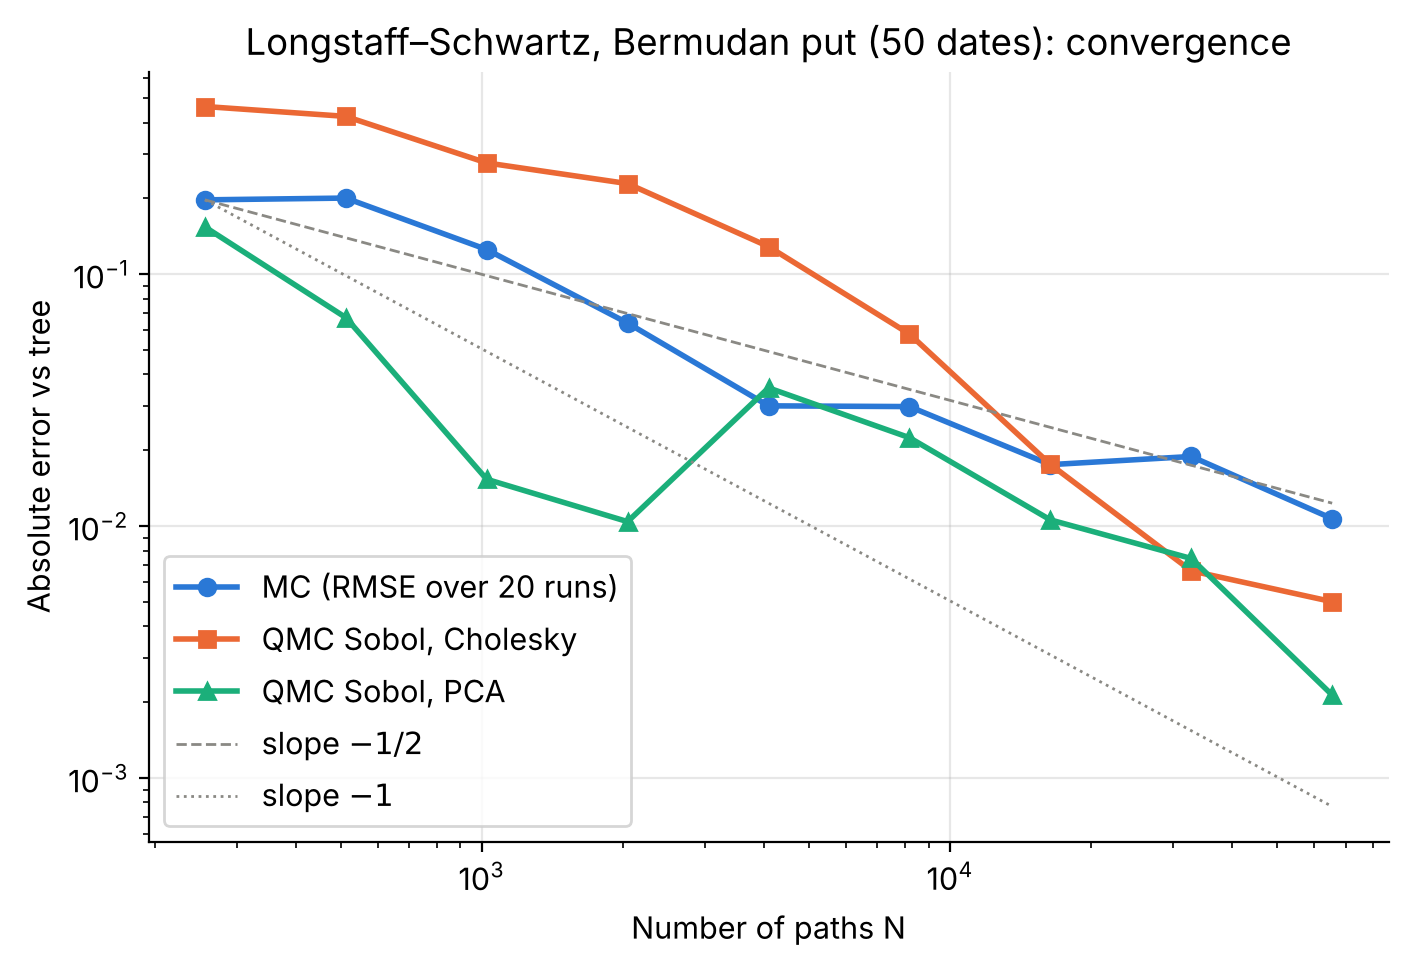

In [16]:
N_values = 2.0**m_values

fig, ax = plt.subplots()
ax.loglog(N_values, rmse_mc, marker="o", color=COLOR_MC, label="MC (RMSE over 20 runs)")
ax.loglog(N_values, err_qmc_chol, marker="s", color=COLOR_CHOL, label="QMC Sobol, Cholesky")
ax.loglog(N_values, err_qmc_pca, marker="^", color=COLOR_PCA, label="QMC Sobol, PCA")

# Reference slopes, anchored at the first MC point
ax.loglog(N_values, rmse_mc[0] * (N_values / N_values[0])**(-0.5), color=COLOR_REF, linestyle="--", linewidth=1, label=r"slope $-1/2$")
ax.loglog(N_values, rmse_mc[0] * (N_values / N_values[0])**(-1.0), color=COLOR_REF, linestyle=":", linewidth=1, label=r"slope $-1$")

ax.set_xlabel("Number of paths N")
ax.set_ylabel("Absolute error vs tree")
ax.set_title(f"Longstaff–Schwartz, Bermudan put ({d} dates): convergence")
ax.legend()
plt.show()

### 5.2 Summary table at $N = 2^{14}$

For the same number of paths, we compare price, error and computing time. The time includes generating the Gaussians, the paths and running LSM.

In [17]:
m = 14
n_runs_table = 20

# Monte Carlo
prices = np.zeros(n_runs_table)
start = time.perf_counter()
for j in range(n_runs_table):
    S = simulate_paths(gaussian_mc(2**m, d, seed=7000 + j), A_chol, d)
    prices[j] = lsm_price(S, put_payoff, DEGREE)
time_mc = (time.perf_counter() - start) / n_runs_table

# Quasi-Monte Carlo
results_qmc = {}
for method in ["cholesky", "pca"]:
    start = time.perf_counter()
    S = simulate_paths(gaussian_qmc(m, d), build_A(d, method), d)
    price = lsm_price(S, put_payoff, DEGREE)
    results_qmc[method] = (price, time.perf_counter() - start)

print(f"N = 2^{m} = {2**m} paths, tree reference = {V_REF:.4f}")
print()
print(f"{'Method':<20}{'Price':>10}{'Error':>12}{'Time (s)':>12}")
print("-" * 54)
print(f"{'MC (mean)':<20}{np.mean(prices):>10.4f}{np.sqrt(np.mean((prices - V_REF)**2)):>12.4f}{time_mc:>12.3f}")
print(f"{'   MC std dev':<20}{np.std(prices, ddof=1):>10.4f}")
for method in ["cholesky", "pca"]:
    price, elapsed = results_qmc[method]
    print(f"{'QMC ' + method:<20}{price:>10.4f}{abs(price - V_REF):>12.4f}{elapsed:>12.3f}")
print()
print("For MC, the 'Error' column is the RMSE over the runs.")

N = 2^14 = 16384 paths, tree reference = 4.4779

Method                   Price       Error    Time (s)
------------------------------------------------------
MC (mean)               4.4882      0.0228       0.078
   MC std dev           0.0209
QMC cholesky            4.4955      0.0176       0.091
QMC pca                 4.4673      0.0106       0.090

For MC, the 'Error' column is the RMSE over the runs.


### 5.3 Regression bias: the role of the basis degree

The error of Longstaff–Schwartz has two sources:
- an **integration error** (statistical in MC, deterministic in QMC), which decreases with $N$;
- a **regression bias**: the polynomial basis only approximates $C_k$, so the exercise strategy is suboptimal. This bias **does not vanish** as $N \to \infty$.

QMC only reduces the first one. Once it becomes small, the bias sets the error floor. We measure it here at $N = 2^{16}$: the MC bias is estimated as the mean of 10 runs minus the reference.

In [18]:
m = 16
n_runs_bias = 10

print(f"N = 2^{m}")
print(f"{'Degree':<8}{'MC bias':>12}{'MC std dev':>16}{'QMC PCA error':>17}")
print("-" * 53)
Z_qmc = gaussian_qmc(m, d)
for degree in [1, 2, 3, 4]:
    prices = np.zeros(n_runs_bias)
    for j in range(n_runs_bias):
        S = simulate_paths(gaussian_mc(2**m, d, seed=9000 + j), A_chol, d)
        prices[j] = lsm_price(S, put_payoff, degree)
    price_qmc = lsm_price(simulate_paths(Z_qmc, A_pca, d), put_payoff, degree)
    print(f"{degree:<8}{np.mean(prices) - V_REF:>12.4f}{np.std(prices, ddof=1):>16.4f}{price_qmc - V_REF:>17.4f}")

N = 2^16
Degree       MC bias      MC std dev    QMC PCA error
-----------------------------------------------------


1            -0.0571          0.0085          -0.0589


2            -0.0102          0.0122          -0.0143


3            -0.0006          0.0121          -0.0036


4             0.0018          0.0112          -0.0021


### 5.4 Counterpoint: the European put on the same paths

To isolate the effect of the exercise boundary, we reuse **exactly the same paths** but keep only the payoff at maturity (European put, exact Black–Scholes reference, no regression). The payoff then depends only on $W_T$:
- with **Cholesky**, $W_T = \sqrt{\Delta t}\,(Z_1 + \dots + Z_d)$ depends on every coordinate with the same weight;
- with **PCA**, $W_T$ is carried mostly by the first components.

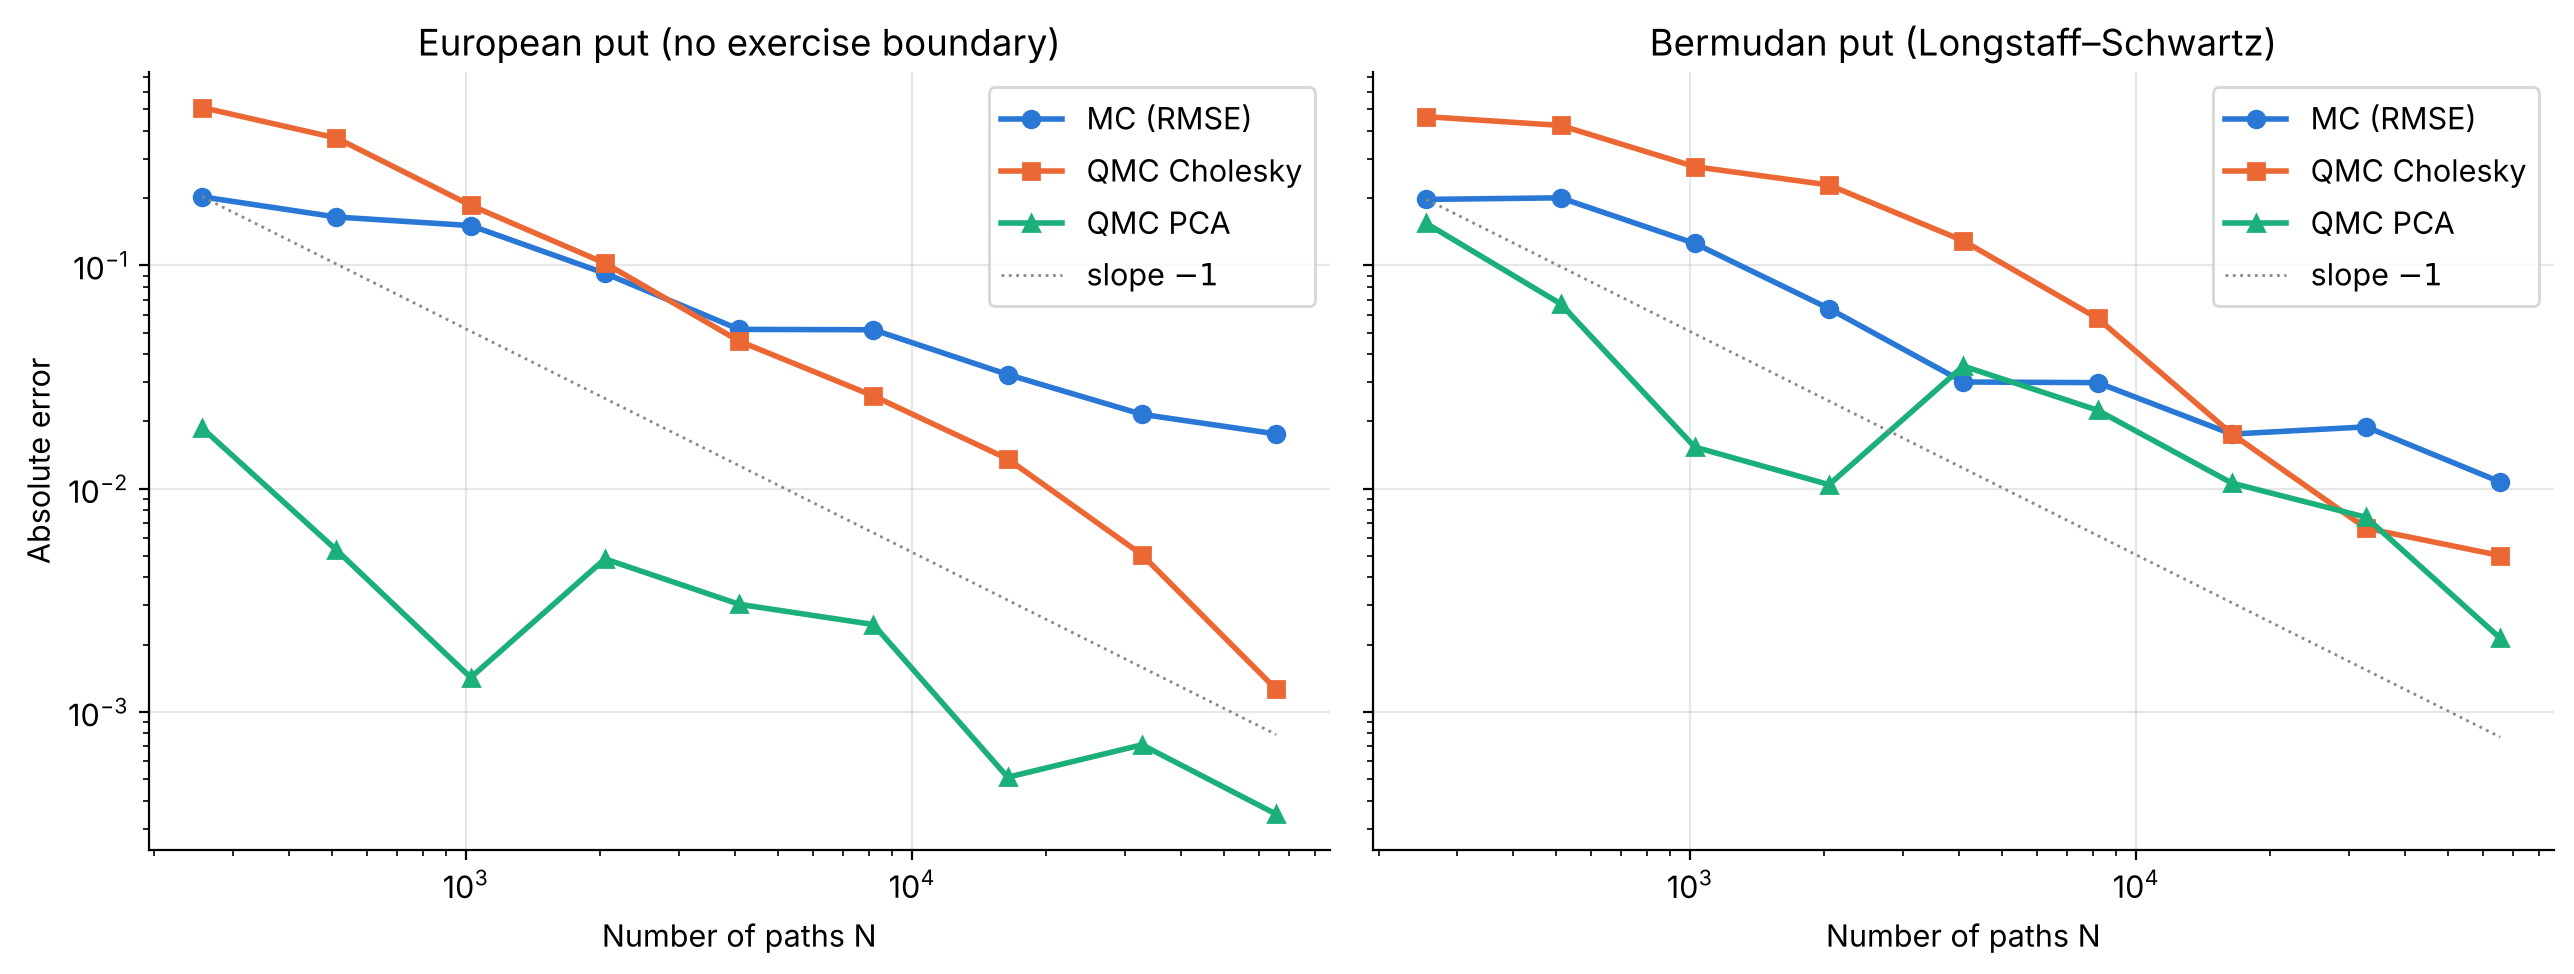

At N = 2^16: QMC PCA / MC gain = 50x (European) vs 5x (Bermudan)


In [19]:
def european_price(S, payoff):
    """European price: discounted mean of the payoff at maturity."""
    return np.exp(-r * T) * np.mean(payoff(S[:, -1]))


V_EURO = bs_price("put")
rmse_mc_euro = np.zeros(len(m_values))
err_chol_euro = np.zeros(len(m_values))
err_pca_euro = np.zeros(len(m_values))

for i in range(len(m_values)):
    m = m_values[i]
    prices = np.zeros(n_runs)
    for j in range(n_runs):
        S = simulate_paths(gaussian_mc(2**m, d, seed=1000 * m + j), A_chol, d)
        prices[j] = european_price(S, put_payoff)
    rmse_mc_euro[i] = np.sqrt(np.mean((prices - V_EURO)**2))

    Z = gaussian_qmc(m, d)
    err_chol_euro[i] = abs(european_price(simulate_paths(Z, A_chol, d), put_payoff) - V_EURO)
    err_pca_euro[i] = abs(european_price(simulate_paths(Z, A_pca, d), put_payoff) - V_EURO)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

axes[0].loglog(N_values, rmse_mc_euro, marker="o", color=COLOR_MC, label="MC (RMSE)")
axes[0].loglog(N_values, err_chol_euro, marker="s", color=COLOR_CHOL, label="QMC Cholesky")
axes[0].loglog(N_values, err_pca_euro, marker="^", color=COLOR_PCA, label="QMC PCA")
axes[0].loglog(N_values, rmse_mc_euro[0] * (N_values / N_values[0])**(-1.0), color=COLOR_REF, linestyle=":", linewidth=1, label=r"slope $-1$")
axes[0].set_title("European put (no exercise boundary)")
axes[0].set_xlabel("Number of paths N")
axes[0].set_ylabel("Absolute error")
axes[0].legend()

axes[1].loglog(N_values, rmse_mc, marker="o", color=COLOR_MC, label="MC (RMSE)")
axes[1].loglog(N_values, err_qmc_chol, marker="s", color=COLOR_CHOL, label="QMC Cholesky")
axes[1].loglog(N_values, err_qmc_pca, marker="^", color=COLOR_PCA, label="QMC PCA")
axes[1].loglog(N_values, rmse_mc[0] * (N_values / N_values[0])**(-1.0), color=COLOR_REF, linestyle=":", linewidth=1, label=r"slope $-1$")
axes[1].set_title("Bermudan put (Longstaff–Schwartz)")
axes[1].set_xlabel("Number of paths N")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"At N = 2^16: QMC PCA / MC gain = {rmse_mc_euro[-1] / err_pca_euro[-1]:.0f}x (European) vs {rmse_mc[-1] / err_qmc_pca[-1]:.0f}x (Bermudan)")

---
## 6. Conclusion

**1. The construction matters more than the sequence.** With exactly the same Sobol points, the Cholesky construction is less accurate than MC for $N \le 2^{13}$, whereas PCA beats MC almost everywhere. The reason is effective dimension: PCA puts 81% of the Brownian variance on the first Sobol coordinate, the best distributed one, and this share does not depend on $d$ (section 2.3). With Cholesky, every coordinate carries the same weight, and the last Sobol dimensions, poorly distributed for small $N$, degrade the estimate.

**2. The QMC gain depends on the smoothness of the payoff.** On the European put, QMC PCA is about 50 times more accurate than MC at $N = 2^{16}$; on the Bermudan, about 5 times. The exercise decision is an indicator function: the integrand is discontinuous along the exercise boundary, which slows QMC down.

**3. Regression bias sets a floor.** The Longstaff–Schwartz bias goes from about $-0.057$ at degree 1 to about $-0.010$ at degree 2, then down to order $10^{-3}$ at degrees 3 and 4. This bias is negligible compared with the MC error at $N = 2^{16}$ (about 0.011), but of the same order as the QMC error: with QMC, the quality of the regression, more than the number of paths, limits the accuracy.

**4. The QMC error is not monotone.** It oscillates from one $N$ to the next (see $N = 2^{12}$): conclusions about QMC must be drawn over a range of $N$, never from a single point.

### Limitations

- **No confidence interval for QMC.** The estimator is deterministic: we can only measure its error because a reference tree is available, which is no longer the case in high dimension (baskets, stochastic volatility models).
- **Bias and integration error are mixed.** The observed QMC error is the sum of both, and they cannot be separated without randomisation.
- **Smoothness.** The exercise decision is an indicator: the integrand is discontinuous, of infinite variation in the sense of Hardy–Krause, and the Koksma–Hlawka bound does not apply as such. The QMC gain is real, but classical theory does not guarantee it.